# Beyond: reconciliation identities, overlays as lines and a regime comparison on one book

- **Level:** 4, Beyond the state of the art
- **Prerequisites:** notebooks 01 to 07 of this topic
- **Reading time:** about 60 minutes

## Objectives

By the end of this notebook you can:

- state claim BS-5 of the SDD in its four parts and say what evidence each part has and what it does not claim;
- run the reconciliation gate on six reporting dates, plant defects in the tables and see which identity names each one, and measure the size of the smallest defect the gate catches;
- show that overlays are separate lines that change the total allowance and nothing else;
- reproduce the non-linearity example, verify the weighted-over-average inequality as a property in the convex regime, and find where it fails;
- check that the three regimes on one synthetic bank reconcile through a bridge in every scenario, and say what that comparison is not.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import dataclasses
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Twelve committed files, from two cases.

- **C06**, the six reporting dates `data/derived/C06/rd-2006-12.json`, `rd-2008-12.json`, `rd-2010-12.json`, `rd-2019-12.json`, `rd-2020-06.json` and `rd-2023-06.json` (SBA 7(a) loans, U.S. Government Works, licence class `mirror-allowed`): the roll-forward of the allowance and of the gross carrying amount (`outputs.reconciliation`), the waterfall, the stage totals and the non-linearity block.
- **C07**, the six scenarios `data/derived/C07/base.json`, `recession.json`, `house-price-fall.json`, `consumer-arrears-shock.json`, `uf-inflation-spike.json` and `combined-severe.json`: Banco Andino, a **synthetic** bank generated and calibrated to public aggregates of the CMF. It is not a real bank and not evidence about any bank. The comparison of the three regimes, the bridge, the overlays and the test rows.

All files were baked by an older engine than the one installed; the notebook prints both versions. **No file was written for this notebook**: every number below is read from these files or computed by the engine on them, and the planted defects are made on copies in memory.

In [2]:
# Load the six C06 dates and the six C07 scenarios and print the engine versions that baked them
from scipy.special import ndtri

from riskvalidation.provisions import ecl as ecl_engine, overlays as ovl, reconciliation as rec, term_structure as tsm
from riskvalidation.validation import ifrs9

LANG = "en"
ROOT = Path("../../..").resolve()
C06_DATES = ["2006-12", "2008-12", "2010-12", "2019-12", "2020-06", "2023-06"]
C07_NAMES = ["base", "recession", "house-price-fall", "consumer-arrears-shock", "uf-inflation-spike", "combined-severe"]


def read(case, name):
    return json.loads((ROOT / "data" / "derived" / case / name).read_text(encoding="utf-8"))


c06 = {d: read("C06", f"rd-{d}.json") for d in C06_DATES}
c07 = {n: read("C07", f"{n}.json") for n in C07_NAMES}
print("C06 baked by engine:", sorted({a["provenance"]["riskvalidation_version"] for a in c06.values()}), "| C07:", sorted({a["provenance"]["riskvalidation_version"] for a in c07.values()}), "| installed engine:", md.version("riskvalidation"))
print("C07 synthetic in every file:", all(a["outputs"]["synthetic"] and a["provenance"]["truth_status"] == "synthetic-calibrated" for a in c07.values()))
print("C07 notice (first file):", c07["base"]["outputs"]["notice"][LANG])

C06 baked by engine: ['0.5.0'] | C07: ['0.5.0'] | installed engine: 0.9.0
C07 synthetic in every file: True
C07 notice (first file): Synthetic data: Banco Andino is a generated bank calibrated to public CMF system aggregates, not a real bank and not evidence about any bank. CMF B-1 is the statutory provision Chilean banks book on loans; the IFRS 9 column is a comparison measure, not the provision Chilean banks book on loans (CNCB A-2 N 5 leaves loans to B-1); BdE Annex 9 is the Spanish GAAP alternative solution. Amounts in CLP.


## Method

Claim **BS-5** of the SDD has four parts. Each one is a statement that can fail, and each is tested below on committed files with the engine.

1. **The IFRS 7 roll-forward closes as a gate.** Twelve identities tie the stage tables to the waterfall, judged by `check_identities` on the tolerance basis $|\mathrm{difference}| \le \mathrm{tolerance} \times \max(1, G)$ with $G$ the sum of the absolute closing amounts of the gross carrying amount rows (notebook 04). A gate is worth its power to detect: the notebook plants defects and measures the size of the smallest one it catches.
2. **Overlays are separate lines.** The total allowance is $\mathrm{LA} = \mathrm{ECL}_{\mathrm{model}} + \sum_k \mathrm{OVL}_k$ and the overlays never enter the model ECL or the stage ECL (BCBS d350, paragraphs 50 and 51; ECB 2024). The test is an invariance: changing the overlays changes the total and leaves the model figures alone.
3. **The non-linearity of the weighted ECL is reproduced.** With the one-factor conditional PD $PD(z) = \Phi\bigl((\Phi^{-1}(PD^{\mathrm{TTC}}) - \sqrt{\rho}\,z)/\sqrt{1-\rho}\bigr)$ (BCBS 2005; Gordy 2003), which is convex where $z \ge \Phi^{-1}(PD^{\mathrm{TTC}})/\sqrt{\rho}$, Jensen's inequality gives $\mathbb{E}[PD(Z)] \ge PD(\mathbb{E}[Z])$: the weighted PD is at least the PD at the weighted mean factor **in the convex regime**, and can be below it outside. The test is a seeded property sweep through the engine's `nonlinearity_test`, plus the reference example and the committed rows.
4. **One synthetic bank is provisioned under three regimes with a gap bridge.** CMF B-1, IFRS 9 as a comparison measure and Bank of Spain Annex 9 (notebook 06). The test is reconciliation: the totals equal the sum of their segments and the B-1 total plus the steps of the bridge equals the IFRS 9 total, in every scenario.

What the claim is not: it is not a validation of any regime or of any bank, it states no compliance claim, and the absence of a public three-regime comparison is what the research (dossiers 02 and 03) found, UNVERIFIED beyond the searches those dossiers record.

## State of the art

What the practice and the research found before this work, with its source:

| Practice | What it states | Source |
|---|---|---|
| IFRS 9 measurement | objective and principles, not formulas: the standard "generally does not prescribe particular detailed methods" | GPPC 2016, section 2.1.1.1; IFRS 9 5.5.17 |
| Reconciliation of the allowance | a disclosure by stage of the opening to the closing allowance and of the gross carrying amount | IFRS 7 35H and 35I |
| Non-linearity | more than one scenario is needed when the loss is not linear in the macro path; GDP-only overlays ignore it and underestimate the mean impact | GPPC 2016, 2.8.1.2; ECB 2024; BCBS d350, paragraph 36(a) |
| Overlays | should be methodology-based, attributed, allocated at parameter level and reflected in staging; about a quarter of the performing-book coverage came from overlays in the ECB sample | ECB 2024; BCBS d350, paragraphs 50 and 51 |
| Chile | loans are provisioned under CMF B-1, not IFRS 9 impairment | CNCB A-2 N 5, B-1 |
| Spain | IFRS 9-type ECL with supervisory alternative solutions | Circular 4/2017, Circular 6/2021 |
| Comparison of the regimes | the persisted research (dossiers 02 and 03) found **no public comparison of the three on one portfolio** | the dossiers' own searches, UNVERIFIED beyond them |

The practice therefore states the identities as a disclosure, the overlays as a principle and the regimes as separate texts. It does not run the identities as a gate with a measured detection threshold, it does not show an overlay invariance, and it does not put the regimes on one book.

## Beyond the state of the art

The four parts of BS-5, each with its test. The evidence files are those of the claim (`data/derived/C06/rd-2008-12.json`, `data/derived/C07/base.json`) and the other dates and scenarios that extend it.

### Part 1: the identities close on six dates

For each C06 date the cell rebuilds the stage rows with the engine, runs `check_identities` (which must return an empty list), prints the number of identities, the largest residual, $G$ and the absolute limit, and compares the light of the engine's own test `reconciliation_identities` with the committed row.

In [3]:
# Rebuild the stage rows of each C06 date and run the identity gate and the engine's own test
def moves(row):
    return {m_["line_id"]: m_["amount"] for m_ in row["movements"]}


def rows_of(art):
    recon = art["outputs"]["reconciliation"]
    allowance = [rec.allowance_rollforward(r["stage"], r["opening"], moves(r), r["closing"]) for r in recon["allowance"]]
    gca = [rec.gca_rollforward(r["stage"], r["opening"], moves(r), r["closing"]) for r in recon["gross_carrying_amount"]]
    lines = [dict(line) for line in art["outputs"]["waterfall"]["lines"]]
    stage_ecl = {r["stage"]: r["ecl"] for r in art["outputs"]["stage_summary"]["rows"]}
    return allowance, gca, lines, stage_ecl


for d, art in c06.items():
    allowance, gca, lines, stage_ecl = rows_of(art)
    residuals = rec.identity_residuals(allowance, gca, lines, stage_ecl)
    G = rec.gross_total(gca)
    test = ifrs9.reconciliation_identities(allowance, gca, lines, stage_ecl, model_id="L1-dth")
    committed = [t for t in art["tests"] if t["test_id"] == "ifrs9.reconciliation_identities"][0]
    print(d, "| identities:", len(residuals), "| failing:", rec.check_identities(allowance, gca, lines, stage_ecl), "| largest residual:", f"{max(residuals.values()):.1e}", "| G (USD millions):", round(G / 1e6, 1), "| limit, USD:", round(1e-6 * G, 1), "|", test.light.value, committed["light"])

2006-12 | identities: 12 | failing: [] | largest residual: 1.5e-05 | G (USD millions): 47124.4 | limit, USD: 47124.4 | green green
2008-12 | identities: 12 | failing: [] | largest residual: 1.2e-07 | G (USD millions): 47247.6 | limit, USD: 47247.6 | green green
2010-12 | identities: 12 | failing: [] | largest residual: 3.8e-06 | G (USD millions): 55459.9 | limit, USD: 55459.9 | green green
2019-12 | identities: 12 | failing: [] | largest residual: 1.5e-05 | G (USD millions): 99603.2 | limit, USD: 99603.2 | green green
2020-06 | identities: 12 | failing: [] | largest residual: 1.3e-05 | G (USD millions): 99710.5 | limit, USD: 99710.5 | green green
2023-06 | identities: 12 | failing: [] | largest residual: 1.2e-07 | G (USD millions): 116761.4 | limit, USD: 116761.4 | green green


### Part 2: a gate that catches planted defects, and its measured threshold

A gate that cannot fail proves nothing. The cell plants six defects of 1,000,000 USD on copies of the 2008 tables, one at a time, and asks which identities fail: a movement of the allowance without its closing, a movement of the gross carrying amount, the waterfall closing, a waterfall line, the stage ECL, and an allowance closing. A second cell then measures the detection threshold: it bisects the size of the first defect between 0 and 100 millions and finds the size at which the gate starts to fail, which should be the tolerance limit $10^{-6} \times G$.

In [4]:
# Plant six defects of one million USD, one at a time, on copies of the 2008 tables
art = c06["2008-12"]
allowance, gca, lines, stage_ecl = rows_of(art)
recon = art["outputs"]["reconciliation"]
D = 1_000_000.0


def bump_allowance(stage_index, line_id, amount, closing_too=False):
    r = recon["allowance"][stage_index]
    new = rec.allowance_rollforward(r["stage"], r["opening"], {**moves(r), line_id: moves(r)[line_id] + (0.0 if closing_too else amount)}, r["closing"] + (amount if closing_too else 0.0))
    return allowance[:stage_index] + [new] + allowance[stage_index + 1:]


def bump_gca(stage_index, line_id, amount):
    r = recon["gross_carrying_amount"][stage_index]
    new = rec.gca_rollforward(r["stage"], r["opening"], {**moves(r), line_id: moves(r)[line_id] + amount}, r["closing"])
    return gca[:stage_index] + [new] + gca[stage_index + 1:]


def bump_line(line_id, amount):
    return [dict(line, amount=line["amount"] + amount) if line["id"] == line_id else dict(line) for line in lines]


cases = {
    "allowance movement, Stage 1, closing unchanged": (bump_allowance(0, "remeasurement", D), gca, lines, stage_ecl),
    "gross amount movement, Stage 2": (allowance, bump_gca(1, "repayments", D), lines, stage_ecl),
    "waterfall closing line": (allowance, gca, bump_line("closing", D), stage_ecl),
    "waterfall remeasurement line": (allowance, gca, bump_line("remeasurement", D), stage_ecl),
    "stage ECL, Stage 1": (allowance, gca, lines, {**stage_ecl, "stage1": stage_ecl["stage1"] + D}),
    "allowance closing, Stage 2": (bump_allowance(1, "remeasurement", D, closing_too=True), gca, lines, stage_ecl),
}
print("untouched tables, failing:", rec.check_identities(allowance, gca, lines, stage_ecl))
for label, args in cases.items():
    failing = rec.check_identities(*args)
    print(f"{label:62s} caught: {bool(failing)} | {failing}")

untouched tables, failing: []
allowance movement, Stage 1, closing unchanged                 caught: True | ['allowance-rollforward:stage1', 'waterfall-lines-equal-movements']
gross amount movement, Stage 2                                 caught: True | ['gca-rollforward:stage2']
waterfall closing line                                         caught: True | ['waterfall-closes', 'waterfall-equals-stage-closings']
waterfall remeasurement line                                   caught: True | ['waterfall-closes', 'waterfall-lines-equal-movements']
stage ECL, Stage 1                                             caught: True | ['stage-closing-equals-ecl:stage1']
allowance closing, Stage 2                                     caught: True | ['allowance-rollforward:stage2', 'waterfall-equals-stage-closings', 'stage-closing-equals-ecl:stage2']


The detection threshold. For a defect of the first kind, the cell asks `check_identities` whether it is caught, bisects the size between 0 and 100 millions of USD for 80 steps, and compares the size where the answer flips with $10^{-6} \times G$. It then lists nine sizes from 1 to 100 million USD, and repeats three of them at a tolerance of $10^{-9}$.

In [5]:
# Measure the detection threshold of the gate by bisection on the size of one defect
def caught(size):
    return bool(rec.check_identities(bump_allowance(0, "remeasurement", size), gca, lines, stage_ecl))


G = rec.gross_total(gca)
low, high = 0.0, 1e8
for _ in range(80):
    middle = 0.5 * (low + high)
    low, high = (low, middle) if caught(middle) else (middle, high)
print("tolerance limit 1e-6 x G, USD:", round(1e-6 * G, 3))
print("largest size not caught, smallest size caught, USD:", round(low, 3), round(high, 3))
print("the threshold equals the limit within 1 USD:", abs(high - 1e-6 * G) < 1.0)
sizes = [10.0 ** k for k in range(0, 9)]
detected = [caught(s) for s in sizes]
for s, c in zip(sizes, detected):
    print("defect, USD", f"{s:12.0f}", "caught:", c)
print("detection at tolerance 1e-9 (limit in USD):", round(1e-9 * G, 2), [bool(rec.check_identities(bump_allowance(0, "remeasurement", s), gca, lines, stage_ecl, tolerance=1e-9)) for s in (10.0, 100.0, 1000.0)])

tolerance limit 1e-6 x G, USD: 47247.616
largest size not caught, smallest size caught, USD: 47247.616 47247.616
the threshold equals the limit within 1 USD: True
defect, USD            1 caught: False
defect, USD           10 caught: False
defect, USD          100 caught: False
defect, USD         1000 caught: False
defect, USD        10000 caught: False
defect, USD       100000 caught: True
defect, USD      1000000 caught: True
defect, USD     10000000 caught: True
defect, USD    100000000 caught: True
detection at tolerance 1e-9 (limit in USD): 47.25 [False, True, True]


### Part 3: overlays are lines, and only the total moves

The cell rebuilds Banco Andino's two overlays as in notebook 04 and passes them to the engine's `portfolio_allowance` with one constructed account per stage that stands for the committed stage ECL, so that the model figures are those of the file. It then multiplies the overlays by 0, 1 and 10 and checks the invariance: the model ECL and the ECL by stage never change, the overlay total and the total allowance change by exactly the overlay amounts. A last check carries an overlay in a Stage 1 closing of C06 and asks `check_identities` whether the stage closing still equals the stage ECL plus the overlay carried there: it fails when the overlay is not in the closing and closes when it is.

In [6]:
# Scale the overlays and check that only the overlay total and the total allowance move
detail = c07["base"]["outputs"]["ifrs9_detail"]
split = {amount: target for target, amount in [t for t in c07["base"]["tests"] if t["test_id"] == "ifrs9.overlay_diagnostics"][0]["extras"]["by_target"].items() if amount}
overlays = [
    ovl.Overlay(id=o["id"], rationale_en=o["label"]["en"], rationale_es=o["label"]["es"], method="expert", target=split[o["amount"]], segment_id=o["segment_id"],
                stage=o["stage"], amount=o["amount"], staging_effect="none", review_date="2026-08-31", currency="CLP")  # review date: a lesson input
    for o in detail["overlays"]
]
by_stage = {r["stage"]: r["ecl"] for r in detail["stage_summary"] if r["stage"] != "poci"}
stage_codes = np.array([1, 2, 3])
ecl12 = np.array([by_stage["stage1"], 0.0, 0.0])
ecl_life = np.array([0.0, by_stage["stage2"], 0.0])
ecl_s3 = np.array([0.0, 0.0, by_stage["stage3"]])
baseline = ecl_engine.portfolio_allowance(stage_codes, ecl12, ecl_life, ecl_s3, overlays=overlays)
for factor in (0, 1, 10):
    scaled = [dataclasses.replace(o, amount=o.amount * factor) for o in overlays]
    result = ecl_engine.portfolio_allowance(stage_codes, ecl12, ecl_life, ecl_s3, overlays=scaled)
    print("overlays x", factor, "| model total same:", result.model_total == baseline.model_total, "| by stage same:", result.by_stage == baseline.by_stage, "| overlay total, CLP millions:", round(result.overlay_total / 1e6, 1), "| total moves by exactly the overlays:", abs(result.total - (result.model_total + result.overlay_total)) < 1e-6)
print("total allowance and committed IFRS 9 provision, CLP millions:", round(baseline.total / 1e6, 1), round(c07["base"]["impact"]["provision_ifrs9"]["value"] / 1e6, 1))
print("overlay lines, never merged:", [(l["id"], l["stage"]) for l in ovl.overlay_lines(overlays)])

allowance, gca, lines, stage_ecl = rows_of(c06["2008-12"])
OVERLAY = ovl.Overlay(id="LESSON", rationale_en="lesson", rationale_es="lección", method="expert", target="pd", segment_id=None, stage=None, amount=10_000_000.0, staging_effect="none", review_date="2026-08-31", currency="USD")
not_carried = rec.check_identities(allowance, gca, lines, stage_ecl, overlays=[OVERLAY])
r1 = recon["allowance"][0]
carried_row = rec.allowance_rollforward("stage1", r1["opening"], {**moves(r1), "overlay-LESSON": OVERLAY.amount}, r1["closing"] + OVERLAY.amount)
carried_lines = [dict(l, amount=l["amount"] + OVERLAY.amount) if l["id"] == "closing" else dict(l) for l in lines] + [{"id": "overlay-LESSON", "kind": "overlay", "overlay_id": "LESSON", "amount": OVERLAY.amount, "stage": None}]
carried = rec.check_identities([carried_row] + allowance[1:], gca, carried_lines, stage_ecl, overlays=[OVERLAY])
print("an overlay of 10 millions not carried in the closing: failing:", not_carried)
print("the same overlay carried in the Stage 1 closing and as a waterfall line: failing:", carried)

overlays x 0 | model total same: True | by stage same: True | overlay total, CLP millions: 0.0 | total moves by exactly the overlays: True
overlays x 1 | model total same: True | by stage same: True | overlay total, CLP millions: 324.1 | total moves by exactly the overlays: True
overlays x 10 | model total same: True | by stage same: True | overlay total, CLP millions: 3241.3 | total moves by exactly the overlays: True
total allowance and committed IFRS 9 provision, CLP millions: 97592.0 97592.0
overlay lines, never merged: [('overlay-OVL-CARDS', 'stage1'), ('overlay-OVL-HOUSING', 'stage2')]
an overlay of 10 millions not carried in the closing: failing: ['stage-closing-equals-ecl:stage1']
the same overlay carried in the Stage 1 closing and as a waterfall line: failing: []


### Part 4: the non-linearity, reproduced and bounded

Three tests. First, the reference example (the lesson inputs of notebook 03: $PD^{\mathrm{TTC}} = 2\%$, $\rho = 0.12$, $z = (+1, 0, -2)$, weights $(0.25, 0.5, 0.25)$) through `nonlinearity_test`. Second, the committed rows: the PD-level index of the six C07 segments recomputed from their weighted PD and PD at the mean factor, and the ECL-level index of the six C06 dates recomputed from the weighted ECL and the ECL at the mean path. Third, a seeded sweep of 4,000 random draws of $(PD^{\mathrm{TTC}}, \rho, z, w)$ through the engine's test, split by whether every scenario factor lies in the convex region $z \ge \Phi^{-1}(PD^{\mathrm{TTC}})/\sqrt{\rho}$. In the convex region the index cannot be negative (Jensen); outside it, it can.

In [7]:
# The reference example and the committed PD-level and ECL-level indexes
example = ifrs9.nonlinearity_test(0.02, 0.12, np.array([1.0, 0.0, -2.0]), np.array([0.25, 0.5, 0.25]), model_id="lesson")
print("reference example: weighted PD and PD at the mean factor (percent), index:", round(100 * example.extras["pd_weighted"], 3), round(100 * example.extras["pd_at_mean_z"], 3), round(example.metric, 4), "|", example.light.value)

segments = [t for t in c07["base"]["tests"] if t["test_id"] == "ifrs9.nonlinearity"]
indexes = [ecl_engine.non_linearity_index(t["extras"]["pd_weighted"], t["extras"]["pd_at_mean_z"]) for t in segments]
print("C07 segments: PD-level index recomputed equals the committed one:", all(abs(i - t["metric"]) < 1e-6 for i, t in zip(indexes, segments)), "| smallest and largest:", round(min(indexes), 3), round(max(indexes), 3))
for d, art in c06.items():
    block = art["outputs"]["non_linearity"]
    index = ecl_engine.non_linearity_index(block["ecl_weighted"], block["ecl_at_mean_path"])
    print(d, "| ECL-level index:", round(index, 5), "| equals committed:", abs(index - block["index"]) < 1e-9, "| weighted at least the mean-path ECL:", index >= 0.0)

reference example: weighted PD and PD at the mean factor (percent), index: 2.681 1.8 0.4898 | green
C07 segments: PD-level index recomputed equals the committed one: True | smallest and largest: 0.156 0.956
2006-12 | ECL-level index: 0.00211 | equals committed: True | weighted at least the mean-path ECL: True
2008-12 | ECL-level index: 0.02121 | equals committed: True | weighted at least the mean-path ECL: True
2010-12 | ECL-level index: -0.00071 | equals committed: True | weighted at least the mean-path ECL: False
2019-12 | ECL-level index: 0.0232 | equals committed: True | weighted at least the mean-path ECL: True
2020-06 | ECL-level index: 0.01279 | equals committed: True | weighted at least the mean-path ECL: True
2023-06 | ECL-level index: 0.00622 | equals committed: True | weighted at least the mean-path ECL: True


The sweep. The cell draws 4,000 cases with a fixed seed: a PD between 0.1% and 20% (log-uniform), a correlation between 0.01 and 0.30, two to five scenarios with factors around a random centre between $-5$ and $+1$, and weights from a Dirichlet distribution. Each goes through `nonlinearity_test`. It counts the draws whose factors are all in the convex region, the negative indexes in each group and the red lights, and ends with one explicit concave example.

In [8]:
# A seeded sweep of random draws through the engine's test, split by the convex region
rng = np.random.default_rng(20261021)
draws = []
for _ in range(4000):
    pd_ttc = float(np.exp(rng.uniform(np.log(0.001), np.log(0.2))))
    rho = float(rng.uniform(0.01, 0.30))
    k = int(rng.integers(2, 6))
    z = rng.normal(rng.uniform(-5.0, 1.0), rng.uniform(0.3, 1.5), k)
    w = rng.dirichlet(np.ones(k))
    result = ifrs9.nonlinearity_test(pd_ttc, rho, z, w)
    convex = bool(np.all(z >= ndtri(pd_ttc) / math.sqrt(rho)))
    draws.append((convex, result.metric, float(np.sum(w * z)), result.light.value, result.extras["gauss_hermite_error"]))
convex_draws = [d for d in draws if d[0]]
other_draws = [d for d in draws if not d[0]]
print("draws:", len(draws), "| all factors in the convex region:", len(convex_draws), "| others:", len(other_draws))
print("convex region: smallest index (never negative):", round(min(d[1] for d in convex_draws), 6), "| negative:", sum(d[1] < 0 for d in convex_draws))
print("outside it: smallest index:", round(min(d[1] for d in other_draws), 4), "| negative:", sum(d[1] < 0 for d in other_draws), "| red lights:", sum(d[3] == "red" for d in other_draws))
print("Gauss-Hermite error at most 1e-9 in every draw:", all(d[4] <= 1e-9 for d in draws))
concave = ifrs9.nonlinearity_test(0.2, 0.3, np.array([-3.0, -4.0]), np.array([0.5, 0.5]), model_id="lesson")
print("a concave example (PD, rho, z): index and light:", (0.2, 0.3, (-3.0, -4.0)), round(concave.metric, 5), concave.light.value, "| convex from z:", round(float(ndtri(0.2) / math.sqrt(0.3)), 3))

draws: 4000 | all factors in the convex region: 3402 | others: 598
convex region: smallest index (never negative): 0.0 | negative: 0
outside it: smallest index: -0.12 | negative: 356 | red lights: 356
Gauss-Hermite error at most 1e-9 in every draw: True
a concave example (PD, rho, z): index and light: (0.2, 0.3, (-3.0, -4.0)) -0.01319 red | convex from z: -1.537


### Part 5: three regimes, one synthetic bank, a bridge in every scenario

The last test is reconciliation over the six scenarios of Banco Andino. For each file the cell checks that the total of each regime equals the sum of its segments plus the unallocated lines, that the B-1 comparable total plus the additional provisions equals the booked B-1 total, and that the B-1 total plus the steps of the bridge equals the IFRS 9 total. It also checks that the file carries the synthetic notice in both languages. It prints the ratio of IFRS 9 to B-1: a statement about the same book under different rules, not about which rule is right.

In [9]:
# Reconcile the totals, the booked B-1 total and the bridge in each of the six scenarios
keys = ("cmf_b1_provision", "ifrs9_provision", "bde_annex9_provision")
checks = {"sums": [], "booked": [], "bridge": [], "notice": []}
for name, art in c07.items():
    out = art["outputs"]
    totals = {k: sum(r[k] for r in out["comparison"]["rows"]) + out["comparison"]["unallocated"][k] for k in keys}
    regimes = {r["regime"]: r["total_provision"] for r in out["regimes"]}
    checks["sums"].append(abs(totals["cmf_b1_provision"] - regimes["cmf-b1"]) < 1.0 and abs(totals["ifrs9_provision"] - regimes["ifrs9"]) < 1.0 and abs(totals["bde_annex9_provision"] - regimes["bde-annex9"]) < 1.0)
    checks["booked"].append(abs(out["b1_detail"]["booked_total"] - (regimes["cmf-b1"] + out["b1_detail"]["additional_provisions"]["amount"])) < 1.0)
    bridge_end = totals["cmf_b1_provision"] + sum(s["amount"] for s in out["gap_bridge"]["steps"])
    checks["bridge"].append(abs(bridge_end - totals["ifrs9_provision"]) < 1.0)
    checks["notice"].append(bool(out["notice"]["en"]) and bool(out["notice"]["es"]) and out["synthetic"])
    print(f"{name:24s} B-1: {regimes['cmf-b1'] / 1e9:8.1f} | IFRS 9: {regimes['ifrs9'] / 1e9:8.1f} | Annex 9: {regimes['bde-annex9'] / 1e9:8.1f} | IFRS 9 / B-1: {regimes['ifrs9'] / regimes['cmf-b1']:6.3f} | bridge residual, CLP: {abs(bridge_end - totals['ifrs9_provision']):.2f}")
print({k: all(v) for k, v in checks.items()}, "| scenarios:", len(c07))

base                     B-1:    152.0 | IFRS 9:     97.6 | Annex 9:     79.6 | IFRS 9 / B-1:  0.642 | bridge residual, CLP: 0.00
recession                B-1:    197.5 | IFRS 9:    169.8 | Annex 9:    116.3 | IFRS 9 / B-1:  0.860 | bridge residual, CLP: 0.00
house-price-fall         B-1:    168.9 | IFRS 9:    128.8 | Annex 9:     94.6 | IFRS 9 / B-1:  0.763 | bridge residual, CLP: 0.00
consumer-arrears-shock   B-1:    178.6 | IFRS 9:    126.3 | Annex 9:     97.3 | IFRS 9 / B-1:  0.707 | bridge residual, CLP: 0.00
uf-inflation-spike       B-1:    166.9 | IFRS 9:    117.4 | Annex 9:     85.6 | IFRS 9 / B-1:  0.703 | bridge residual, CLP: 0.00
combined-severe          B-1:    275.8 | IFRS 9:    327.8 | Annex 9:    191.6 | IFRS 9 / B-1:  1.189 | bridge residual, CLP: 0.00
{'sums': True, 'booked': True, 'bridge': True, 'notice': True} | scenarios: 6


### The tests, drawn

The left panel draws the gate's detection of a defect of growing size on the 2008 tables, on logarithmic axes: the vertical line is the tolerance limit $10^{-6} \times G$ and the steps show which sizes the gate catches. The right panel draws the sweep of the non-linearity index against the weighted mean factor, in the convex region (blue) and outside it (red): the blue points never fall below zero, the red ones can.

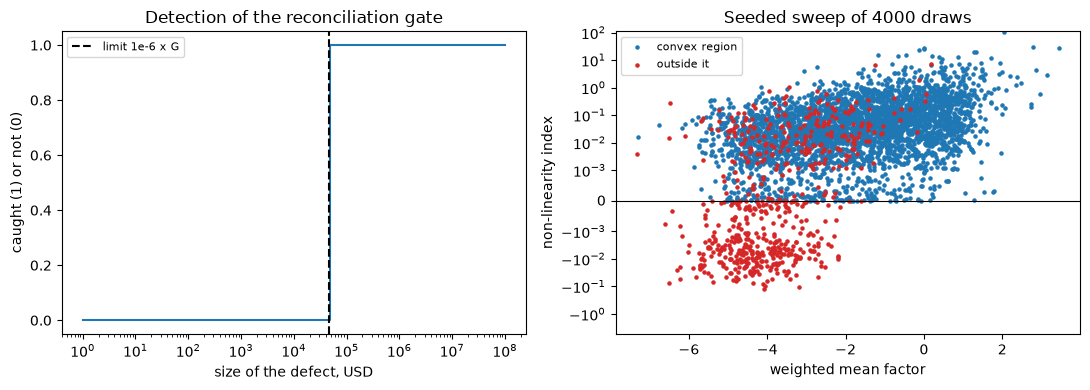

In [10]:
# Draw the detection of the gate by defect size and the non-linearity sweep by region
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
grid = np.logspace(0, 8, 160)
left.step(grid, [1.0 if caught(s) else 0.0 for s in grid], where="post", color="tab:blue")
left.axvline(1e-6 * G, color="black", linestyle="--", label="limit 1e-6 x G")
left.set_xscale("log")
left.set_xlabel("size of the defect, USD")
left.set_ylabel("caught (1) or not (0)")
left.set_title("Detection of the reconciliation gate")
left.legend(fontsize=8)

right.scatter([d[2] for d in convex_draws], [d[1] for d in convex_draws], s=5, color="tab:blue", label="convex region")
right.scatter([d[2] for d in other_draws], [d[1] for d in other_draws], s=5, color="tab:red", label="outside it")
right.axhline(0.0, color="black", linewidth=0.8)
right.set_yscale("symlog", linthresh=1e-3)
right.set_xlabel("weighted mean factor")
right.set_ylabel("non-linearity index")
right.set_title("Seeded sweep of 4000 draws")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Results

- **The identities close on six dates.** On every C06 date the twelve identities hold and `check_identities` returns an empty list. The largest residual is 1.5e-05 USD (2006-12, 2019-12), 1.3e-05 (2020-06), 3.8e-06 (2010-12) and 1.2e-07 (2008-12 and 2023-06), against absolute limits of 47,124.4, 47,247.6, 55,459.9, 99,603.2, 99,710.5 and 116,761.4 USD (one millionth of $G$, which runs from 47.1 to 116.8 billions of USD). The engine's own test is green on all six dates, as the committed rows are. The residuals are rounding of the stored numbers, at least nine orders of magnitude below the limit.
- **The gate catches what it should, and its threshold is the tolerance.** Six defects of 1,000,000 USD are caught, each by the identity that names it: a movement of the allowance without its closing is caught by `allowance-rollforward:stage1` and `waterfall-lines-equal-movements`, a gross amount movement by `gca-rollforward:stage2`, the waterfall closing by `waterfall-closes` and `waterfall-equals-stage-closings`, a waterfall line by `waterfall-closes` and `waterfall-lines-equal-movements`, the stage ECL by `stage-closing-equals-ecl:stage1` and an allowance closing by three identities. The bisection finds that defects up to 47,247.6 USD pass and larger ones fail: the threshold equals $10^{-6} \times G$ within 1 USD. Sizes from 1 to 10,000 USD pass, from 100,000 USD up they fail, and at a tolerance of $10^{-9}$ the limit is 47.25 USD and 100 USD is caught.
- **Overlays change the total and nothing else.** With the overlays multiplied by 0, 1 and 10 the model total and the ECL by stage stay equal; the overlay total is 0, 324.1 and 3,241.3 millions of CLP and the total allowance moves by exactly that. At the committed amounts the total allowance is 97,592.0 millions, equal to the committed IFRS 9 provision, and the overlays stay two lines (`overlay-OVL-CARDS` in Stage 1, `overlay-OVL-HOUSING` in Stage 2). An overlay of 10 millions that is not carried in the Stage 1 closing makes `stage-closing-equals-ecl:stage1` fail, and carrying it in the closing and as a waterfall line closes every identity: the identities tie the overlay to its stage.
- **The non-linearity example is reproduced.** The weighted PD is 2.681% and the PD at the mean factor 1.800%, an index of 0.4898. On the committed C07 segments the PD-level index recomputed from the stored PDs equals the committed one and runs from 0.156 to 0.956.
- **The weighted ECL is not always above the mean-path ECL, and the claim says where it holds.** On the committed C06 dates the ECL-level index is 0.00211, 0.02121, $-0.00071$, 0.0232, 0.01279 and 0.00622: five of six are at or above zero and 2010-12 is below, which the engine reads as amber. The sweep of 4,000 seeded draws through `nonlinearity_test` shows why the statement needs its qualifier: of 3,402 draws with every scenario factor in the convex region the smallest index is 0.0 and none is negative; of 598 draws with a factor outside it 356 are negative (down to $-0.12$) and all of those are red. A concave example (PD 0.2, $\rho = 0.3$, $z = -3$ and $-4$) gives $-0.01319$, red, and the convex region starts at $z = -1.537$. The Gauss-Hermite error is at most 1e-9 in every draw.
- **Three regimes reconcile in every scenario.** For the six Banco Andino files the totals equal the sum of their segments plus the unallocated lines, the booked B-1 total equals the comparable total plus the additional provisions, the bridge from B-1 to IFRS 9 closes with a residual of 0.00 CLP, and every file carries the synthetic notice in both languages. IFRS 9 over B-1 runs from 0.642 in the base to 1.189 in the combined severe case.

What BS-5 claims, as the evidence holds it: the roll-forward closes as a gate whose measured threshold is one millionth of the gross carrying amount (not one millionth of a unit of money); overlays are separate lines; the weighted PD is at least the PD at the mean factor in the convex regime, with the example reproduced; one synthetic bank is provisioned under three regimes with a bridge that reconciles. What it does not claim: that any regime is right, that the committed ECL-level inequality holds on every date (it does not on 2010-12), that Banco Andino resembles a real bank, or that no public comparison of the three regimes exists beyond what the research found.

## Summary

- BS-5 has four parts, and each is a test on committed files with the engine: the reconciliation gate, the overlay invariance, the non-linearity and the three-regime reconciliation.
- The gate closes on six dates, catches six planted defects by name, and its measured detection threshold is $10^{-6} \times G$, tens of thousands of USD on these books.
- Overlays are lines: changing them moves the total allowance by exactly their amount and moves nothing else; the identities tie each one to its stage.
- The weighted PD is at least the PD at the mean factor in the convex regime and can be below it outside; the committed ECL-level index was below zero once in six dates.
- One synthetic bank under CMF B-1, IFRS 9 and Annex 9 reconciles through a bridge in six scenarios, and the ranking of the regimes changes with the scenario.
- The claim is bounded by its evidence: no regime is validated, the bank is synthetic and the absence of a public comparison is what the research found.

**What to try next.** Plant a defect of your own size in the Stage 3 row and bisect its threshold; scale the overlays by a negative factor and read what `check_identities` says; change the seed of the sweep. The claim text and its evidence are in the SDD section `## Beyond the state of the art`.

## References

- IASB, IFRS 9 Financial Instruments (July 2014), as endorsed by Commission Regulation (EU) 2016/2067, paragraphs 5.5 and B5.5, and the IFRS 7 amendments 35A to 35N. https://eur-lex.europa.eu/legal-content/EN/TXT/HTML/?uri=CELEX:32016R2067
- GPPC (2016), The implementation of IFRS 9 impairment requirements by banks, 17 June 2016, sections 2.1.1, 2.7.2 and 2.8.1.2. https://www.globalpublicpolicycommittee.org/wp-content/uploads/2022/12/gppc-ifrs9-implementation-considerations-20160617.pdf
- ECB Banking Supervision (2024), IFRS 9 overlays and model improvements for novel risks, July 2024. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.IFRS9novelrisks_202407~5e0eb30b5c.en.pdf
- BCBS (2015), Guidance on credit risk and accounting for expected credit losses (d350), paragraphs 36, 50 and 51 and annex paragraph A26. https://www.bis.org/bcbs/publ/d350.htm
- BCBS (2005), An explanatory note on the Basel II IRB risk weight functions, section 4.2: the one-factor model. https://www.bis.org/publications/explanatory-note-basel-ii-irb-risk-weight-functions.pdf
- Gordy, M. B. (2003), A risk-factor model foundation for ratings-based bank capital rules, Journal of Financial Intermediation 12(3), 199-232. https://doi.org/10.1016/S1042-9573(03)00040-8
- CMF Chile, Compendio de Normas Contables para Bancos (CNCB), Chapters A-2 (N 5) and B-1 (N 2, N 3, N 4 and N 9), Circular 2.346. https://www.cmfchile.cl/portal/normativa/624/articles-29177_doc_pdf.pdf
- Banco de España, Circular 6/2021 of 22 December (BOE-A-2021-21666): the tables of points 140, 144 and 172, applicable from 30 June 2022. https://www.boe.es/buscar/doc.php?id=BOE-A-2021-21666